# code_152 · Target adaptation, missing histories and label budgets

**Book:** section29.3. Restart and run all cells in the pinned environment. Explicit one-time public checkpoint acquisition is required; see the asset guide. Inference then runs offline on CPU with local byte-hash verification. Use the [quickstart](../README.md), [guide](../CHAPTER_29_GUIDE.md), [execution evidence](../CHAPTER_29_EXECUTION.md), [assets](../CHAPTER_29_ASSETS.md) and [registry](../CODE_EXAMPLES.md#code_152). Prerequisites: arrays, forecasting boundaries and Chapters24–26. Allow one minute for execution and30–60minutes to interpret the controls.

All task records are locally generated teaching inputs, not field observations. A generated series or equation family is not evidence of operational validity. Named forecasting checkpoints are identified explicitly; own shared forecasters and learned stencils are not Poseidon, Aurora, TimesFM or Chronos reproductions. Every fit, selected transformation, label budget and final assessment has a declared boundary. CPU float32 neural computations use one thread; numerical references use float64 where appropriate. The literature cutoff is18October2026; access21October2026 does not extend it.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np,scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(3752);torch.use_deterministic_algorithms(True)
START=time.perf_counter();SEED=3752;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 3752


<a id="adaptation-budget"></a>
 ## Count target labels used by an actual adaptation route
 Chronos-BoltTiny supplies frozen12-step medians from128historical values. Each of two domains has40generated series:24calibration,8development and8final. The first domain samples a daily cycle hourly (period24); the second samples it every half-hour (period48), with a changed trend. A shared missing-history mask removes10% of historical values. Forward fill uses only previous admitted observations, including a first-observation fallback to the first observed context value; it cannot see the forecast horizon. For budgets2/8/24whole calibration series, a ridge residual head maps each native forecast and its within-context slope to its observed residual.8development series choose ridge strength0.1/10; final8series choose nothing. Frozen native forecasts, this fitted head, a label-budget seasonal-bias correction remain separate. This is output adaptation, not native transformer fine-tuning.


Pinned local model files verified; Hub offline mode is enabled.


W1021 13:38:40.909000 53380 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


,domain,cadence_hours,label_budget_series,calibration_series_used,calibration_scalar_labels_used,selection_series,model,final_series,MAE
0,Hourly,1.0,2,0,0,0,Frozen Bolt,8,0.154403
1,Hourly,1.0,2,2,24,8,Residual head,8,0.159633
2,Hourly,1.0,2,2,24,0,Seasonal bias,8,0.249931
3,Hourly,1.0,8,0,0,0,Frozen Bolt,8,0.154403
4,Hourly,1.0,8,8,96,8,Residual head,8,0.143298
5,Hourly,1.0,8,8,96,0,Seasonal bias,8,0.197705
6,Hourly,1.0,24,0,0,0,Frozen Bolt,8,0.154403
7,Hourly,1.0,24,24,288,8,Residual head,8,0.150611
8,Hourly,1.0,24,24,288,0,Seasonal bias,8,0.183035
9,Half-hourly,0.5,2,0,0,0,Frozen Bolt,8,0.364034


,domain,budget,ridge_strength,development_MAE,paired_final_MAE_difference,series_bootstrap95
0,Hourly,2,10.0,0.152272,0.005230,"[-0.02475415623196222, 0.03922457063493097]"
1,Hourly,8,10.0,0.150348,-0.011105,"[-0.02908919141594877, 0.00544250246641572]"
2,Hourly,24,0.1,0.148041,-0.003793,"[-0.01034481769670343, 0.0029318808907361433]"
3,Half-hourly,2,10.0,0.527446,0.235515,"[0.002015021807076174, 0.4472474500746802]"
4,Half-hourly,8,10.0,0.234375,-0.068726,"[-0.23683461456201207, 0.12395276449502217]"
5,Half-hourly,24,0.1,0.234604,-0.066246,"[-0.2110229469757315, 0.07778506198139762]"


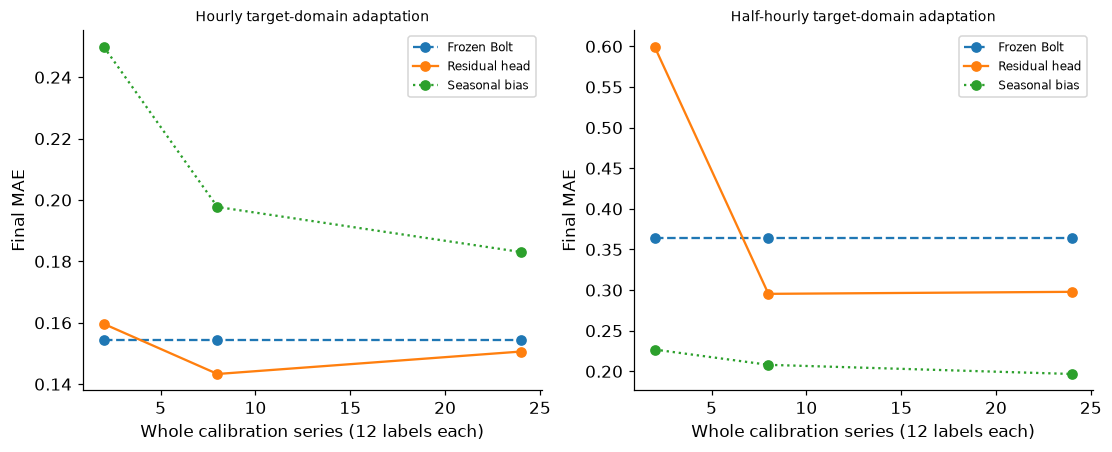

In [2]:
import os
from pathlib import Path
os.environ['HF_HUB_OFFLINE']='1';os.environ['HF_HUB_DISABLE_PROGRESS_BARS']='1'
ASSETS={'bolt': {'repository': 'amazon/chronos-bolt-tiny', 'revision': 'a0e552de83495b5c28c14c71c374f3e33280b340', 'files': [{'filename': 'README.md', 'bytes': 8659, 'sha256': 'cc7f60bc7290b5e6146589dae9842a3c9b59d254e9d1d65fc2ef127f3c2498cd', 'cache_relative_path': 'build/model-cache/models--amazon--chronos-bolt-tiny/snapshots/a0e552de83495b5c28c14c71c374f3e33280b340/README.md'}, {'filename': 'config.json', 'bytes': 1120, 'sha256': '278f0086733031635fb1c861cb01c1bad6477420c7fcb19381a2993e335785e0', 'cache_relative_path': 'build/model-cache/models--amazon--chronos-bolt-tiny/snapshots/a0e552de83495b5c28c14c71c374f3e33280b340/config.json'}, {'filename': 'model.safetensors', 'bytes': 34622352, 'sha256': '75068728d376d2bec670379eeef4bfb4d24c0cfe24d957451f8d19b447030a32', 'cache_relative_path': 'build/model-cache/models--amazon--chronos-bolt-tiny/snapshots/a0e552de83495b5c28c14c71c374f3e33280b340/model.safetensors'}], 'licence': 'Apache-2.0'}}
MODEL_PATHS={}
ASSET_ROOT=next((root for root in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (root/'build/model-cache').is_dir()),Path.cwd().parent)
for name,model in ASSETS.items():
 for file in model['files']:
  path=ASSET_ROOT/file['cache_relative_path']
  if not path.is_file():raise FileNotFoundError('Acquire explicit Chapter29 models first: .venv/bin/python scripts/acquire_chapter29_models.py')
  blob=path.read_bytes();assert len(blob)==file['bytes'] and hashlib.sha256(blob).hexdigest()==file['sha256']
 MODEL_PATHS[name]=path.parent
print('Pinned local model files verified; Hub offline mode is enabled.')

import importlib.metadata
from chronos import BaseChronosPipeline
from transformers.utils import logging as transformer_logging
transformer_logging.disable_progress_bar()
from sklearn.linear_model import Ridge
for package in ['chronos-forecasting','transformers','accelerate']:VERSIONS[package]=importlib.metadata.version(package)
bolt=BaseChronosPipeline.from_pretrained(str(MODEL_PATHS['bolt']),device_map='cpu',dtype=torch.float32,local_files_only=True)
frozen=hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in bolt.model.parameters())).hexdigest();budgets=[2,8,24];rows=[];details=[];all_final={}
def fill_past(x):
    y=x.copy();valid=np.flatnonzero(np.isfinite(y));assert len(valid)>0;y[:valid[0]]=y[valid[0]]
    for k in range(valid[0]+1,len(y)):
        if not np.isfinite(y[k]):y[k]=y[k-1]
    return y
for domain,period,cadence in [('Hourly',24,1.0),('Half-hourly',48,.5)]:
    t=np.arange(204);values=[]
    for j in range(40):
        amplitude=rng.uniform(.6,2);phase=rng.uniform(0,2*np.pi);trend=rng.uniform(.001,.007) if domain=='Hourly' else rng.uniform(.012,.022);values.append(7+rng.uniform(-2,2)+amplitude*np.sin(2*np.pi*t/period+phase)+trend*t+rng.normal(0,.15,len(t)))
    values=np.array(values,dtype=np.float32);raw=values[:,64:192].copy();missing=rng.random(raw.shape)<.1;raw[missing]=np.nan;context=np.array([fill_past(row) for row in raw]);truth=values[:,192:204];assert np.isfinite(context).all()
    with torch.no_grad():q=bolt.predict(torch.tensor(context),prediction_length=12).numpy()
    native=q[:,4];seasonal=context[:,-period:-period+12];slope=(context[:,-12:].mean(1)-context[:,-24:-12].mean(1))/12;lead=np.arange(1,13);features=np.stack([native,context[:,-1,None]+slope[:,None]*lead, np.broadcast_to(lead/12,(40,12))],axis=2)
    per_final={};frozen_error=np.abs(native[32:]-truth[32:]).mean(1);per_final['Frozen']=frozen_error
    for budget in budgets:
        options=[]
        for alpha in [.1,10]:
            fit=Ridge(alpha=alpha).fit(features[:budget].reshape(-1,3),(truth[:budget]-native[:budget]).reshape(-1));prediction=native[24:32]+fit.predict(features[24:32].reshape(-1,3)).reshape(8,12);options.append((float(np.mean(np.abs(prediction-truth[24:32]))),alpha,fit))
        selected=min(options,key=lambda r:r[0]);adapted=native[32:]+selected[2].predict(features[32:].reshape(-1,3)).reshape(8,12);bias=(truth[:budget]-seasonal[:budget]).mean(0);seasonal_adapted=seasonal[32:]+bias
        for name,pred in [('Frozen Bolt',native[32:]),('Residual head',adapted),('Seasonal bias',seasonal_adapted)]:rows.append({'domain':domain,'cadence_hours':cadence,'label_budget_series':budget,'calibration_series_used':0 if name=='Frozen Bolt' else budget,'calibration_scalar_labels_used':0 if name=='Frozen Bolt' else budget*12,'selection_series':8 if name=='Residual head' else 0,'model':name,'final_series':8,'MAE':float(np.mean(np.abs(pred-truth[32:])))})
        paired=np.abs(adapted-truth[32:]).mean(1)-frozen_error;bootstrap=paired[rng.integers(0,8,size=(2000,8))].mean(1);details.append({'domain':domain,'budget':budget,'ridge_strength':selected[1],'development_MAE':selected[0],'paired_final_MAE_difference':float(paired.mean()),'series_bootstrap95':np.quantile(bootstrap,[.025,.975]).tolist()});per_final[f'Head {budget}']=np.abs(adapted-truth[32:]).mean(1)
    all_final[domain]=per_final
    # Intervention: withheld values do not enter the forward-fill procedure.
    altered=values.copy();altered[:,192:]+=999;np.testing.assert_array_equal(np.array([fill_past(row) for row in np.where(missing,np.nan,altered[:,64:192])]),context)
assert frozen==hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in bolt.model.parameters())).hexdigest()
RESULTS.update(domains=2,series_per_domain=40,calibration_series_available=24,development_series=8,final_series=8,horizon=12,context=128,missing_probability=.1,budgets=budgets,ridge_candidates=[.1,10],comparisons=rows,paired_assessments=details,frozen_checkpoint_unchanged=True,adaptation='Ridge output residual head; no native checkpoint fine-tuning',future_imputation_intervention_difference=0.0);display(pd.DataFrame(rows));display(pd.DataFrame(details))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,domain in zip(axes,['Hourly','Half-hourly']):
    for name,style in [('Frozen Bolt','--'),('Residual head','-'),('Seasonal bias',':')]:ax.plot(budgets,[next(r['MAE'] for r in rows if r['domain']==domain and r['model']==name and r['label_budget_series']==b) for b in budgets],marker='o',linestyle=style,label=name)
    ax.set(xlabel='Whole calibration series (12 labels each)',ylabel='Final MAE',title=domain+' target-domain adaptation');ax.legend(fontsize=8)
plt.show()


<a id="clock-and-selection-accounting"></a>
 ## State the adaptation and confidence boundary
 A frozen forecast uses no calibration outcomes to update network weights, yet its128-point historical context still contains target-domain observations. The residual head uses12outcomes per admitted calibration series plus96development outcomes for model selection. Those selection labels do not disappear when the nominal fitting budget is small. Whole-series bootstrapping compares paired final errors descriptively; eight generated final series cannot establish broad deployment savings. Covariate support is absent from this executed release. A future weather measurement is unavailable even if its column exists, whereas a previously scheduled intervention may be known; a model API accepting an array cannot decide that distinction. Native fine-tuning would require new optimization/data/selection budgets and is not silently credited to this head.


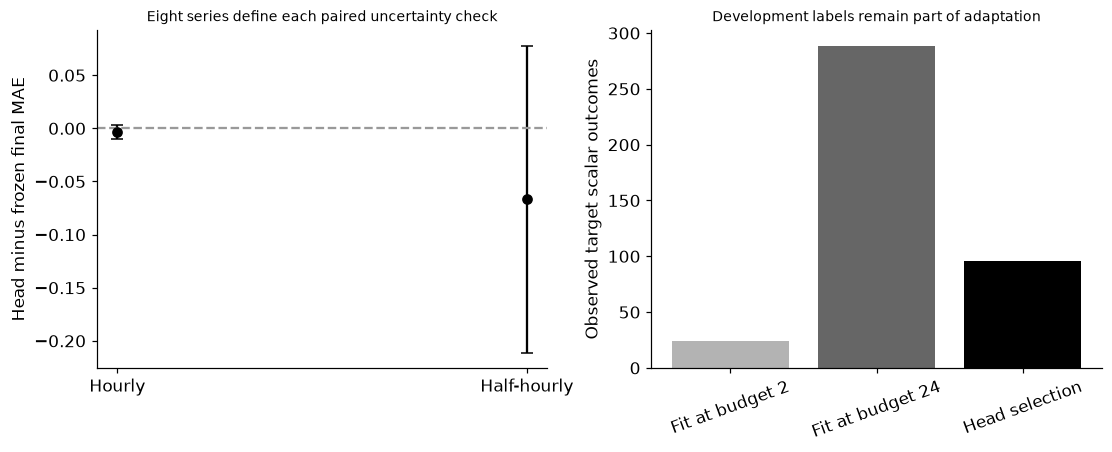

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));subset=[d for d in details if d['budget']==24];means=np.array([d['paired_final_MAE_difference'] for d in subset]);intervals=np.array([d['series_bootstrap95'] for d in subset]);axes[0].errorbar([0,1],means,yerr=np.vstack([means-intervals[:,0],intervals[:,1]-means]),fmt='o',capsize=4,color='black');axes[0].axhline(0,linestyle='--',color='.6');axes[0].set(xticks=[0,1],xticklabels=['Hourly','Half-hourly'],ylabel='Head minus frozen final MAE',title='Eight series define each paired uncertainty check');axes[1].bar(['Fit at budget 2','Fit at budget 24','Head selection'],[24,288,96],color=['.7','.4','black']);axes[1].set(ylabel='Observed target scalar outcomes',title='Development labels remain part of adaptation');axes[1].tick_params(axis='x',rotation=20);plt.show()
assert len(rows)==18 and len(details)==6 and all(np.isfinite(r['MAE']) for r in rows)


In [4]:
summary={'example_id':'code_152','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual frozen ChronosBolt forecast across cadence regimes', 'causal historical imputation and input contracts', 'target-label residual adaptation with separate selection and assessment', 'independent-series uncertainty for label-budget comparisons', 'temporal overlap and future-covariate availability interventions'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual frozen ChronosBolt forecast across cadence regimes", "causal historical imputation and input contracts", "target-label residual adaptation with separate selection and assessment", "independent-series uncertainty for label-budget comparisons", "temporal overlap and future-covariate availability interventions"], "elapsed_seconds": 1.224, "example_id": "code_152", "hardware": "Darwin arm64 CPU", "results": {"adaptation": "Ridge output residual head; no native checkpoint fine-tuning", "budgets": [2, 8, 24], "calibration_series_available": 24, "comparisons": [{"MAE": 0.1544032245874405, "cadence_hours": 1.0, "calibration_scalar_labels_used": 0, "calibration_series_used": 0, "domain": "Hourly", "final_series": 8, "label_budget_series": 2, "model": "Frozen Bolt", "selection_series": 0}, {"MAE": 0.15963274366636243, "cadence_hours": 1.0, "calibration_scalar_labels_used": 24, "calibration_series_used": 2, "domain": "Hourly", "final_serie